# Do full practice authority laws move nurse practitioners?

**An open question in health economics, asked of the universe of nurse practitioners, month by month.**

Twenty-seven states and DC now let nurse practitioners (NPs) evaluate, diagnose, treat and prescribe without a physician's supervision or a collaborative agreement. This is *full practice authority* (FPA). Whether it changes the supply of NPs, and through which margin, matters for access to primary care and is contested:

* Markowitz and Adams (NBER WP 26896) find with the National Sample Survey of Registered Nurses that scope-of-practice restrictions are "not strong determinants of many labor market decisions", except that hours and self-employment rise without oversight requirements.
* Dillender, Lo Sasso, Phelan and Richards (JHR 2026) find with job postings that FPA raises employer demand and NP earnings and reallocates NPs toward self-employment, but "only mildly" increases employment.
* Perry (2012) finds with 1991 to 2003 survey data that NPs are less likely to leave a state that grants more authority.
* Bae, Norris, Shakya and Timmons (SSRN 4402185, 2023) compare Maryland, which adopted FPA in October 2015, with Pennsylvania using annual NPPES counts from 2016 to 2021. Maryland's border counties have 22 more NPs per 100,000 residents. They write that NPPES data were "not available prior to 2016", that it "does not allow us to account for provider mobility", and that without pre-2016 trends "we cannot perform a difference in differences estimation".

All three limits come from using NPPES as a snapshot. This notebook uses the monthly history instead: every NP's practice state and sole-proprietor flag on every monthly file since April 2011. It (1) replicates and extends the Maryland comparison with a pre-period and with mobility, then (2) runs the staggered-adoption design across every state that adopted FPA inside the monthly window, for four outcomes: the stock of NPs, entry of new NPs, cross-state moves, and independence (sole-proprietor status).

Every table is built in DuckDB SQL over the export, in the cell where the argument needs it, with the reasoning just above. The Python is the estimation and the figures.

The point of the notebook is the data, not a verdict. Read the estimates as what a researcher would get on day one, before the choices (regional controls, population weights, time-in-practice rules, anticipation) that a paper would have to make.

In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
from differences import ATTgt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

EXPORT = Path(os.environ.get("NPPES_EXPORT", "../../export")).resolve()
assert (EXPORT / "manifest.json").exists(), f"{EXPORT} is not a complete export: set NPPES_EXPORT"

# One view per export table. The views read Parquet lazily; nothing is copied.
con = duckdb.connect()
con.execute("SET VARIABLE export = ?", [str(EXPORT)])
con.execute("""
CREATE VIEW provider AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider/*/*.parquet', hive_partitioning = true);
CREATE VIEW provider_taxonomy AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider_taxonomy/*/*.parquet', hive_partitioning = true);
CREATE VIEW snapshots AS
SELECT * FROM read_csv(getvariable('export') || '/snapshots.csv');
""");

## 1. When each state adopted FPA

The treatment dates are the month the statute or rule took effect, from McMichael and Markowitz (NBER WP 28192, Table 2) for 1998 to 2020, extended with the Massachusetts (January 2021), New York (April 2022, NPs with 3,600 hours) and Kansas (July 2022) laws. [`data/SOURCES.md`](data/SOURCES.md) has the citations. Each state has a `coding`: `always` (FPA before 1998), `statute` (took effect in the month given) or `never` (no FPA through 2026). Florida is flagged `partial`, because its 2020 law covers primary care NPs only. The second classification is the American Association of Nurse Practitioners (AANP) map, which disagrees on Illinois, Virginia, West Virginia and Florida; we use it for a sensitivity check.

In [2]:
con.execute("""
CREATE TABLE states AS              -- the 50 states and DC, with two-digit FIPS codes
SELECT state, fips FROM read_csv('data/state_fips.csv', all_varchar = true);

CREATE TABLE fpa_dates AS
SELECT f.state,
       f.coding,
       strptime(f.fpa_effective, '%Y-%m')::DATE AS fpa_effective,   -- first day of the month
       coalesce(f.partial = 'Y', false) AS partial,
       a.state IS NOT NULL AS aanp_full_practice,
       f.note
FROM read_csv('data/np_fpa_dates.csv', all_varchar = true) f
LEFT JOIN read_csv('data/aanp_full_practice_2026.csv', all_varchar = true) a USING (state);
""")
n = dict(con.sql("SELECT coding, count(*) FROM fpa_dates GROUP BY coding").fetchall())
window = con.sql("""
SELECT state, strftime(fpa_effective, '%Y-%m') AS fpa_effective, partial, aanp_full_practice, note
FROM fpa_dates
WHERE coding = 'statute' AND fpa_effective >= DATE '2011-04-01'
ORDER BY fpa_effective, state
""").df()
print(f"{n['always']} states had FPA before 1998, {n['never']} never adopted it, "
      f"{n['statute']} adopted by statute, of which {len(window)} inside the monthly window:")
window

9 states had FPA before 1998, 19 never adopted it, 23 adopted by statute, of which 18 inside the monthly window:


,state,fpa_effective,partial,aanp_full_practice,note
0,VT,2011-06,False,True,"Time-in-practice: 2,400 hours or 24 months"
1,ND,2011-10,False,True,NaN
2,RI,2012-02,False,True,NaN
3,NV,2013-07,False,True,TIP applies only to Schedule II prescribing
4,CT,2014-07,False,True,"Time-in-practice: 2,000 hours over 3 years"
5,MN,2015-01,False,True,"Time-in-practice: 2,080 hours"
6,NE,2015-03,False,True,"Time-in-practice: 2,000 hours (reduced later)"
7,DE,2015-09,False,True,NaN
8,MD,2015-10,False,True,McMichael & Markowitz code Oct 2010 (attestati...
9,UT,2016-05,False,True,AANP dates Utah FPA to 2023 when SB 36 removed...


## 2. Build the NP panel

### Who counts as a nurse practitioner

We keep every version of every individual whose primary taxonomy was *ever* a nurse practitioner code: `363L` is Nurse Practitioner (all specialties) in the NUCC taxonomy. The primary taxonomy is the slot CMS flags `primary_taxonomy = 'Y'`. The loader sorts flagged slots first, so we take slot 1 and require the flag: when no slot is flagged, slot 1 is only the code that sorts first, and when CMS flags more than one (472 versions), slot 1 is the first of them. Keeping the whole history, not only the NP versions, is what lets us see an RN become an NP. `is_np` marks the versions where the primary taxonomy is an NP code. It is NULL, unknown, on a version with no flagged primary taxonomy: about 9,000 versions, most from 2007 to 2009. They are 1.2% of the NPs in April 2011, under 0.5% from 2016 and none by 2026.

"Individual" is decided per NPI (any version with `entity_type = '1'`), not per version. When CMS deactivates an NPI, the final version is a stub with only `npi` and `deactivation_date`. The stub has no entity type, and it is the only version that dates the exit. On the stub `is_np` is NULL.

In [3]:
con.execute("""
CREATE TABLE np_versions AS
WITH ever_np AS (
    SELECT DISTINCT t.npi
    FROM provider_taxonomy t
    JOIN (SELECT DISTINCT npi FROM provider WHERE entity_type = '1') USING (npi)
    WHERE t.slot = 1 AND t.primary_taxonomy = 'Y' AND t.taxonomy_code LIKE '363L%'
)
SELECT p.npi, p.effective_date, p.end_date, p.close_reason,
       p.practice_state, p.practice_postal_code, p.sole_proprietor,
       p.deactivation_date,
       t.taxonomy_code AS primary_taxonomy,
       t.taxonomy_code LIKE '363L%' AS is_np
FROM provider p
JOIN ever_np USING (npi)
LEFT JOIN provider_taxonomy t ON t.npi = p.npi AND t.effective_date = p.effective_date AND t.slot = 1 AND t.primary_taxonomy = 'Y'
""")
print("{:,} NPs, {:,} versions".format(*con.sql("SELECT count(DISTINCT npi), count(*) FROM np_versions").fetchone()))

538,881 NPs, 1,841,752 versions


### Events

Each version is compared with the one before it for the same NPI (`lag` over `effective_date`), and a change becomes a dated event. For NP status the comparison is with the last version whose status is known (`lag(is_np IGNORE NULLS)`), so a version with no flagged primary taxonomy neither ends nor starts an NP spell. Counting it as "not an NP" instead would record about 4,200 new NPs as switching into NP in the month CMS filled in the flag, and add about 330 exits and re-entries. The date is the snapshot that first showed it.

* **Entry**: the first version that is an NP, either a new NPI (no earlier version with a known status) or the version where the taxonomy switched to NP.
* **Move**: an NP version whose practice state differs from the previous version's.
* **Sole proprietor**: CMS codes it `Y`, `N` or `X` (not answered). `N` or `X` to `Y` is a switch in, and the reverse is a switch out.
* **Exit**, three ways, symmetric with entry: the taxonomy switches away from NP, the NPI leaves the file (`close_reason = 'absent'`, on an NP version or an unknown one after an NP version), or it is deactivated. A deactivation stub has no state, so the exit takes the state of the version before it.

The NULL `is_np` on a stub or an unknown version needs no special case. SQL's three-valued logic leaves those rows out of both `is_np` and `NOT is_np`, so neither is ever an entry, and a stub counts only through the deactivation rule.

In [4]:
con.execute("""
CREATE TABLE np_events AS
WITH v AS (
    SELECT *,
           lag(is_np IGNORE NULLS) OVER w AS prev_np,
           lag(practice_state) OVER w AS prev_state,
           lag(sole_proprietor) OVER w AS prev_sp,
           lag(deactivation_date) OVER w AS prev_deactivation_date
    FROM np_versions
    WINDOW w AS (PARTITION BY npi ORDER BY effective_date)
)
SELECT npi, effective_date AS date, 'entry' AS event, practice_state AS state, NULL::VARCHAR AS from_state,
       CASE WHEN prev_np IS NULL THEN 'new_npi' ELSE 'switched_taxonomy' END AS detail
FROM v WHERE is_np AND (prev_np IS NULL OR prev_np = false)
UNION ALL
SELECT npi, effective_date, 'move', practice_state, prev_state, NULL
FROM v WHERE is_np AND prev_state IS NOT NULL AND practice_state IS NOT NULL AND practice_state <> prev_state
UNION ALL
SELECT npi, effective_date, 'became_sole_proprietor', practice_state, NULL, prev_sp
FROM v WHERE is_np AND prev_sp IN ('N', 'X') AND sole_proprietor = 'Y'
UNION ALL
SELECT npi, effective_date, 'left_sole_proprietor', practice_state, NULL, sole_proprietor
FROM v WHERE is_np AND prev_sp = 'Y' AND sole_proprietor IN ('N', 'X')
UNION ALL
SELECT npi, effective_date, 'exit', prev_state, NULL, 'switched_taxonomy'
FROM v WHERE prev_np AND NOT is_np AND deactivation_date IS NULL
UNION ALL
SELECT npi, end_date, 'exit', practice_state, NULL, 'absent'
FROM v WHERE coalesce(is_np, prev_np) AND close_reason = 'absent'
UNION ALL
SELECT npi, effective_date, 'exit', coalesce(practice_state, prev_state), NULL, 'deactivated'
FROM v WHERE deactivation_date IS NOT NULL AND prev_deactivation_date IS NULL AND (is_np OR prev_np)
""")
con.sql("SELECT event, count(*) AS events_since_2007 FROM np_events GROUP BY event ORDER BY events_since_2007 DESC").df()

,event,events_since_2007
0,entry,541397
1,move,86378
2,left_sole_proprietor,20653
3,exit,16998
4,became_sole_proprietor,9054


### The state-month panel

A version is in force on date `d` when `effective_date <= d < end_date`, where a NULL `end_date` means still current. A range join of the versions against the snapshot dates therefore gives the NP count each monthly file would have shown. We use the snapshots from April 2011, when the archive becomes monthly. May 2013 is missing, and events in a month without a snapshot drop out of the flows.

Flows come from `np_events`. A move counts at its destination (`move`) and at its origin (`move_out`). Population is the Census estimate for the snapshot's year, with the last Census year (2024) carried forward to the last snapshot's year. `t` is months since April 2011, and `g` is the adoption month on the same clock (NULL if the state never adopted). The final query stops the build if any state-month has no population.

In [5]:
con.execute("""
CREATE TABLE monthly_snapshots AS
SELECT as_of_date FROM snapshots WHERE as_of_date >= DATE '2011-04-01';

CREATE TABLE state_population AS
WITH census AS (SELECT state, year, population FROM read_csv('data/state_population.csv')),
     last_census AS (SELECT max(year) AS year FROM census),
     last_snapshot AS (SELECT max(year(as_of_date)) AS year FROM snapshots)
SELECT state, year, population FROM census
UNION ALL
SELECT c.state, unnest(generate_series(l.year + 1, s.year)), c.population
FROM census c, last_census l, last_snapshot s WHERE c.year = l.year;

CREATE TABLE np_state_month AS
WITH stock AS (
    SELECT v.practice_state AS state, date_trunc('month', s.as_of_date)::DATE AS month,
           count(*) AS nps, count(*) FILTER (WHERE v.sole_proprietor = 'Y') AS sole_proprietors
    FROM monthly_snapshots s
    JOIN np_versions v ON v.effective_date <= s.as_of_date AND (v.end_date IS NULL OR v.end_date > s.as_of_date)
    WHERE v.is_np AND v.practice_state IN (SELECT state FROM states)
    GROUP BY ALL
),
events AS (
    SELECT *, date_trunc('month', date)::DATE AS month FROM np_events WHERE state IN (SELECT state FROM states)
),
flows AS (
    SELECT state, month,
           count(*) FILTER (WHERE event = 'entry') AS entry,
           count(*) FILTER (WHERE event = 'exit') AS exit,
           count(*) FILTER (WHERE event = 'move') AS move
    FROM events GROUP BY ALL
),
move_out AS (
    SELECT from_state AS state, month, count(*) AS move_out FROM events WHERE event = 'move' GROUP BY ALL
)
SELECT s.state, s.month, year(s.month) AS year, s.nps, s.sole_proprietors,
       coalesce(f.entry, 0) AS entry, coalesce(f.exit, 0) AS exit,
       coalesce(f.move, 0) AS move, coalesce(o.move_out, 0) AS move_out,
       pop.population, d.fpa_effective, d.coding, d.partial, d.aanp_full_practice,
       s.nps / pop.population * 1e5 AS nps_per_100k,
       ln(s.nps / pop.population * 1e5) AS log_nps_per_100k,
       s.sole_proprietors / s.nps AS sp_share,
       date_diff('month', DATE '2011-04-01', s.month) AS t,
       date_diff('month', DATE '2011-04-01', d.fpa_effective)::DOUBLE AS g
FROM stock s
JOIN fpa_dates d USING (state)
LEFT JOIN flows f USING (state, month)
LEFT JOIN move_out o USING (state, month)
LEFT JOIN state_population pop ON pop.state = s.state AND pop.year = year(s.month)
ORDER BY s.state, s.month;

SELECT CASE WHEN count(*) > 0 THEN error('a snapshot year has no population row') END
FROM np_state_month WHERE population IS NULL;
""")
panel = con.table("np_state_month").df()
panel[["state", "month", "nps", "entry", "move", "move_out", "sole_proprietors", "nps_per_100k", "fpa_effective"]].tail(3)

,state,month,nps,entry,move,move_out,sole_proprietors,nps_per_100k,fpa_effective
9483,WY,2026-08-01,793,4,4,2,181,134.952,1998-01-01
9484,WY,2026-09-01,802,9,3,2,184,136.483,1998-01-01
9485,WY,2026-10-01,806,3,2,1,185,137.164,1998-01-01


## 3. Maryland and Pennsylvania, with the years the published comparison could not see

Bae et al. compare March counts from 2016 on. The panel starts the same comparison in 2011, four and a half years before Maryland's October 2015 adoption, and adds the moves between the two states.

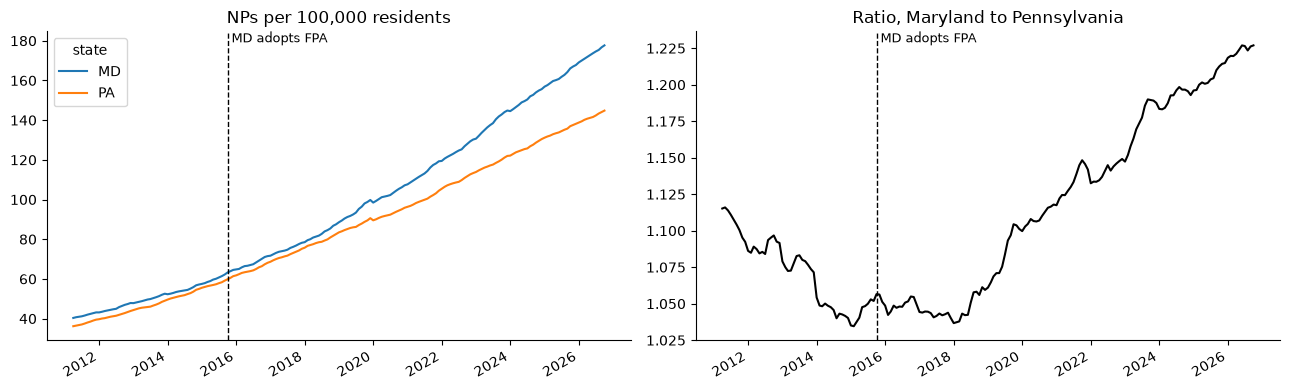

,MD,PA,PA_to_MD,MD_to_PA,MD_growth_%,PA_growth_%
year,,,,,,
2012,2581,5139,5,6,NaN,NaN
2013,2872,5776,5,7,11.3,12.4
2014,3155,6460,8,10,9.9,11.8
2015,3501,7208,19,11,11.0,11.6
2016,3955,8060,10,13,13.0,11.8
2017,4408,8956,10,20,11.5,11.1
2018,4834,9874,13,13,9.7,10.3
2019,5475,10829,19,17,13.3,9.7
2020,6192,11792,15,11,13.1,8.9


In [6]:
md_pa = panel[panel.state.isin(["MD", "PA"])].pivot(index="month", columns="state", values="nps_per_100k")
adopt = pd.Timestamp("2015-10-01")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
md_pa.plot(ax=axes[0]); axes[0].set_title("NPs per 100,000 residents")
(md_pa.MD / md_pa.PA).plot(ax=axes[1], color="k"); axes[1].set_title("Ratio, Maryland to Pennsylvania")
for ax in axes:
    ax.axvline(adopt, color="k", ls="--", lw=1); ax.set_xlabel("")
    ax.text(adopt, ax.get_ylim()[1], " MD adopts FPA", va="top", fontsize=9)
plt.tight_layout(); plt.show()

# March counts, as in the published comparison, with the moves between the two states each year
con.sql("""
WITH march AS (
    SELECT year, max(nps) FILTER (WHERE state = 'MD') AS MD, max(nps) FILTER (WHERE state = 'PA') AS PA
    FROM np_state_month WHERE state IN ('MD', 'PA') AND month(month) = 3 GROUP BY year
),
moves AS (
    SELECT year(date) AS year,
           count(*) FILTER (WHERE from_state = 'PA' AND state = 'MD') AS PA_to_MD,
           count(*) FILTER (WHERE from_state = 'MD' AND state = 'PA') AS MD_to_PA
    FROM np_events WHERE event = 'move' GROUP BY 1
)
SELECT year, MD, PA, PA_to_MD, MD_to_PA,
       round(100 * (MD / lag(MD) OVER (ORDER BY year) - 1), 1) AS "MD_growth_%",
       round(100 * (PA / lag(PA) OVER (ORDER BY year) - 1), 1) AS "PA_growth_%"
FROM march LEFT JOIN moves USING (year)
ORDER BY year
""").df().set_index("year")

Three things the published comparison could not say:

1. **Pre-trend.** From 2012 to 2016 the two states grew at the same pace (Maryland 52%, Pennsylvania 56%), and from 2016 to 2021 Maryland pulled ahead (71% against 57%). But the ratio panel is more careful than the growth rates: Maryland's relative density was *falling* from 2011 to 2014, flat from 2014 to 2018, and rising only from 2018. The divergence starts about two and a half years after adoption, which is consistent with Maryland's time-in-practice rule (18 months of collaboration before independence) and also with something else happening in 2018. A snapshot comparison from 2016 on cannot tell those apart; the monthly series at least shows when the break is.
2. **Mobility is not the channel.** NPs moving from Pennsylvania to Maryland number ten to twenty a year, and about as many go the other way. The gap is far larger than the net flow.
3. **The gap keeps widening** through 2026, five years past their sample.

The border-county version of the same comparison, using the ZIP to county crosswalk and the Census county adjacency file, is in section 7.

## 4. All adoptions at once: descriptive event studies

For each state that adopted FPA inside the monthly window, NP density indexed to 100 in the adoption month, against the same index for the states that never adopted. Each panel is one cohort; the dashed line is adoption. The cohorts are the full-scope laws that took effect inside the monthly window, so Florida is left out.

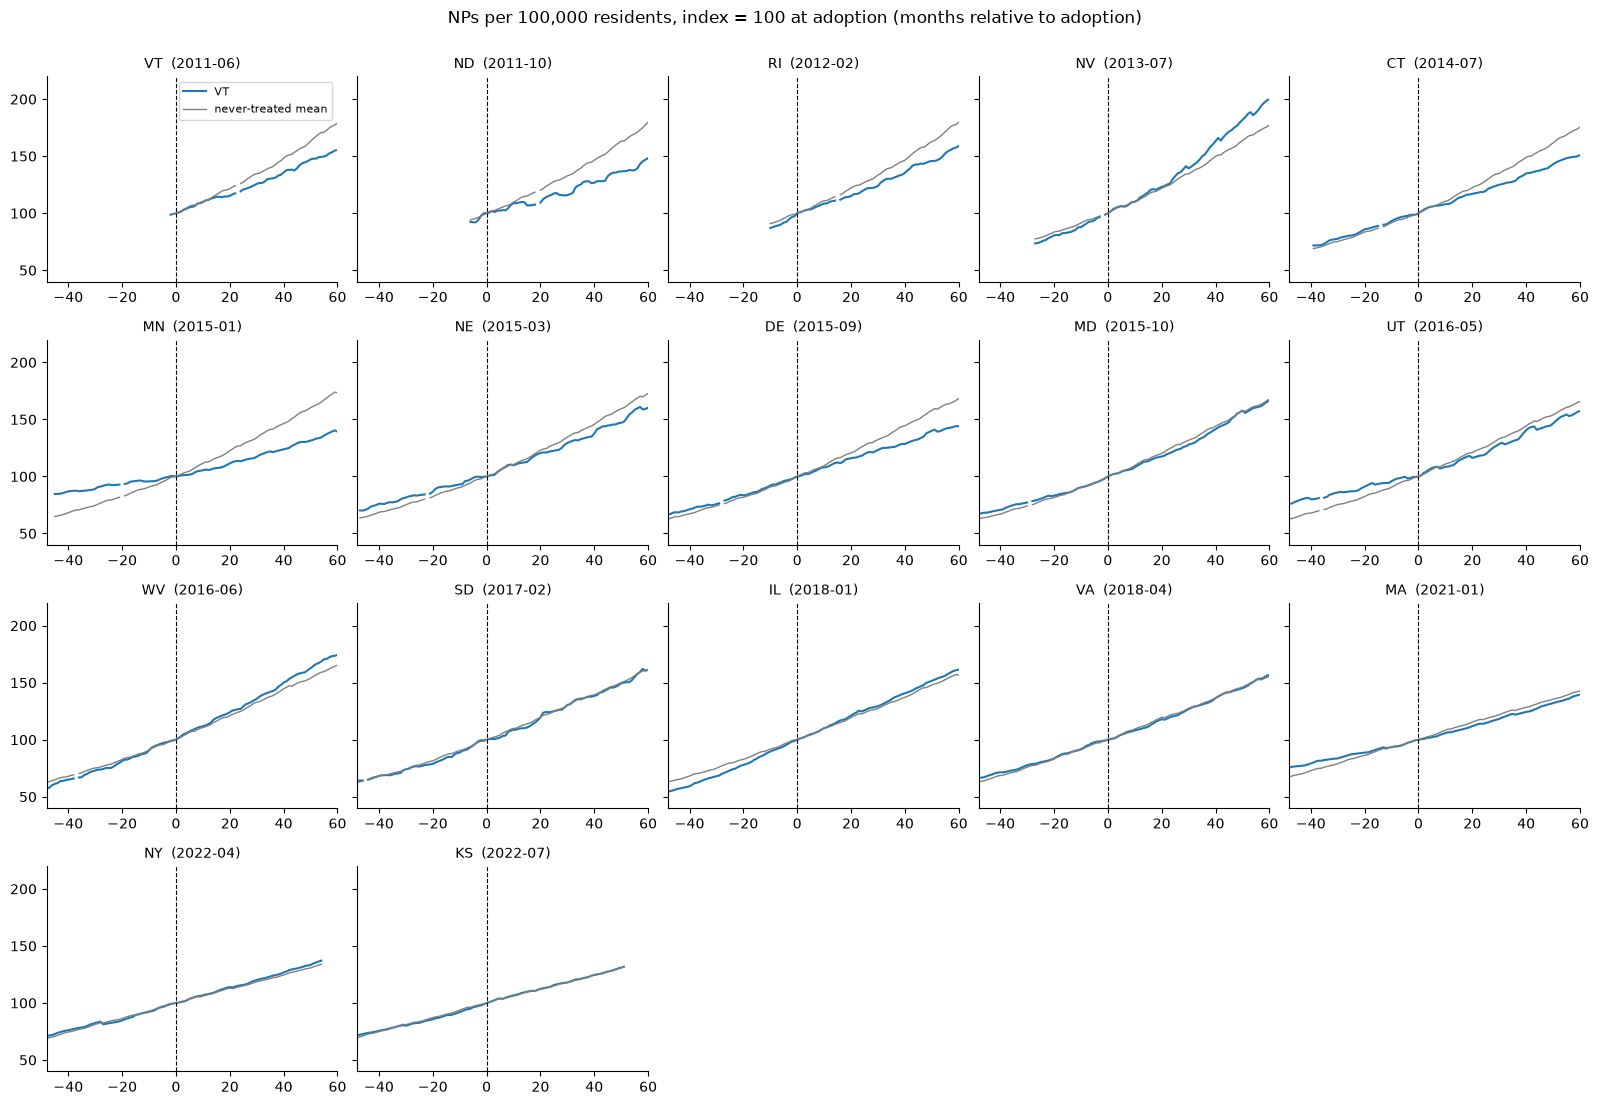

In [7]:
never = panel[panel.coding == "never"].groupby("t").nps_per_100k.mean()
con.execute("""
CREATE TABLE fpa_cohorts AS
SELECT state, fpa_effective FROM fpa_dates
WHERE coding = 'statute' AND fpa_effective >= DATE '2011-04-01' AND NOT partial
ORDER BY fpa_effective, state
""")
cohorts = con.table("fpa_cohorts").df()
fig, axes = plt.subplots(4, 5, figsize=(16, 11), sharey=True)
for ax, (_, r) in zip(axes.flat, cohorts.iterrows()):
    s = panel[panel.state == r.state].set_index("t").nps_per_100k
    g = int(panel.loc[panel.state == r.state, "g"].iloc[0])
    if g not in s.index:
        ax.set_visible(False); continue
    rel = s / s[g] * 100; nrel = never / never[g] * 100
    k = range(-48, 61)
    ax.plot(k, [rel.get(g + i, np.nan) for i in k], label=r.state)
    ax.plot(k, [nrel.get(g + i, np.nan) for i in k], color="grey", lw=1, label="never-treated mean")
    ax.axvline(0, color="k", ls="--", lw=0.8); ax.set_title(f"{r.state}  ({r.fpa_effective:%Y-%m})", fontsize=10)
    ax.set_xlim(-48, 60); ax.set_ylim(40, 220)
for ax in axes.flat[len(cohorts):]: ax.set_visible(False)
axes[0, 0].legend(fontsize=8); fig.suptitle("NPs per 100,000 residents, index = 100 at adoption (months relative to adoption)", y=1.0)
plt.tight_layout(); plt.show()

Before adoption most cohorts track the never-treated mean (Minnesota and Illinois are the exceptions, with slower and faster pre-trends). After adoption more cohorts fall below the never-treated mean than above it: Vermont, North Dakota, Rhode Island, Connecticut, Minnesota, Nebraska, Delaware, Utah and Massachusetts grow more slowly than the states that never adopted, Nevada and West Virginia faster, and Maryland, South Dakota, Illinois, Virginia, New York and Kansas stay on the line. This is the picture the regressions below summarize. It is worth seeing raw first, because the never-treated group is dominated by fast-growing Sun Belt states, and "slower than Texas and Florida" is not the same as "slower than it would have been".

## 5. Staggered difference-in-differences

Treatment is staggered, so we use estimators that do not weight already-treated states as controls: Callaway and Sant'Anna's group-time ATT (the `differences` package, never-treated controls, quarterly to keep the number of group-time cells manageable) and Gardner's two-stage DID2S (`pyfixest`, monthly) for the dynamic plot. States with FPA before 1998, states that adopted before April 2011 and Florida (primary care only) are dropped. Standard errors are clustered by state.

Outcomes, all at the state-month level:

| Outcome | Definition |
|---|---|
| `log_nps_per_100k` | log NPs per 100,000 residents |
| `entry_rate` | new NPs (first appearance, or taxonomy switch into NP) per 1,000 NPs in the state, per quarter |
| `move_rate`, `move_out_rate` | NPs moving into / out of the state per 1,000 NPs, per quarter |
| `sp_share` | share of the state's NPs flagged sole proprietor |

The estimation sample is the never-treated states plus the cohorts. `sid` numbers the states. The quarterly version takes levels and shares from the last month of each quarter and sums the flows. Each flow rate is per 1,000 NPs of the quarter's mean stock. `t` and `g` count quarters from 2011Q2.

In [8]:
con.execute("""
CREATE TABLE did_state_month AS
SELECT dense_rank() OVER (ORDER BY state) - 1 AS sid, *
FROM np_state_month
WHERE coding = 'never' OR state IN (SELECT state FROM fpa_cohorts);

CREATE TABLE did_state_quarter AS
WITH q AS (
    SELECT state, sid, date_trunc('quarter', month)::DATE AS quarter,
           arg_max(log_nps_per_100k, month) AS log_nps_per_100k,
           arg_max(sp_share, month) AS sp_share,
           sum(entry) AS entry, sum(move) AS move, sum(move_out) AS move_out,
           avg(nps) AS nps,
           any_value(fpa_effective) AS fpa_effective,
           any_value(aanp_full_practice) AS aanp_full_practice
    FROM did_state_month GROUP BY ALL
)
SELECT *,
       entry / nps * 1000 AS entry_rate,
       move / nps * 1000 AS move_rate,
       move_out / nps * 1000 AS move_out_rate,
       date_diff('quarter', DATE '2011-04-01', quarter) AS t,
       date_diff('quarter', DATE '2011-04-01', date_trunc('quarter', fpa_effective))::DOUBLE AS g
FROM q
ORDER BY state, quarter;
""");

In [9]:
quarterly = con.table("did_state_quarter").df()          # g is NaN for the never-treated states
outcomes = {"log_nps_per_100k": "log NPs per 100k", "entry_rate": "entries per 1,000 NPs per quarter",
            "move_rate": "in-moves per 1,000 NPs per quarter", "move_out_rate": "out-moves per 1,000 NPs per quarter", "sp_share": "sole-proprietor share"}
pre = quarterly[quarterly.g.notna() & (quarterly.t < quarterly.g)]
print(f"{quarterly.state.nunique()} states: {quarterly[quarterly.g.notna()].state.nunique()} treated cohorts, "
      f"{quarterly[quarterly.g.isna()].state.nunique()} never treated")

results, dynamics = [], {}
for y, label in outcomes.items():
    att = ATTgt(data=quarterly.set_index(["sid", "t"]), cohort_column="g")
    att.fit(formula=y, control_group="never_treated", progress_bar=False)
    s = att.aggregate("simple")
    results.append({"outcome": label, "ATT": s.iloc[0, 0], "se": s.iloc[0, 1], "pre-adoption mean, treated states": pre[y].mean()})
    dynamics[y] = att.aggregate("event")
pd.DataFrame(results).set_index("outcome")

36 states: 17 treated cohorts, 19 never treated


,ATT,se,"pre-adoption mean, treated states"
outcome,,,
log NPs per 100k,-0.051,0.034,4.112
"entries per 1,000 NPs per quarter",-0.552,4.430,32.512
"in-moves per 1,000 NPs per quarter",-0.548,0.886,5.413
"out-moves per 1,000 NPs per quarter",0.587,0.613,6.416
sole-proprietor share,0.004,0.006,0.141


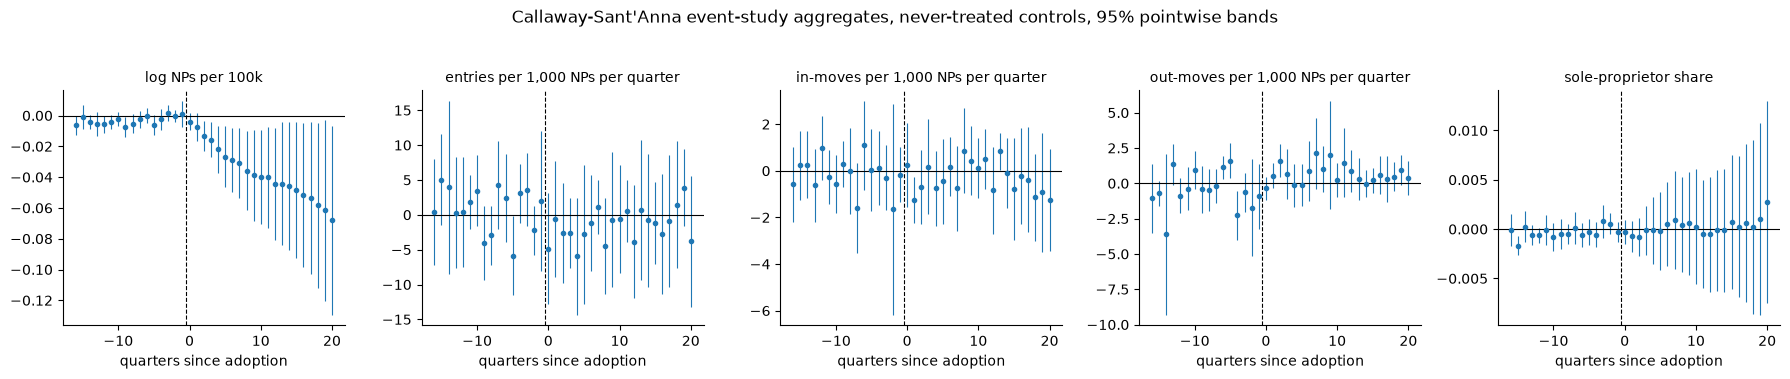

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (y, label) in zip(axes, outcomes.items()):
    d = dynamics[y]; k = d.index.get_level_values(-1) if isinstance(d.index, pd.MultiIndex) else d.index
    k = np.asarray(k, dtype=float); keep = (k >= -16) & (k <= 20)
    ax.errorbar(k[keep], d.iloc[:, 0].values[keep], yerr=1.96 * d.iloc[:, 1].values[keep], fmt="o", ms=3, lw=0.8)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(-0.5, color="k", ls="--", lw=0.8)
    ax.set_title(label, fontsize=10); ax.set_xlabel("quarters since adoption")
fig.suptitle("Callaway-Sant'Anna event-study aggregates, never-treated controls, 95% pointwise bands", y=1.04)
plt.tight_layout(); plt.show()

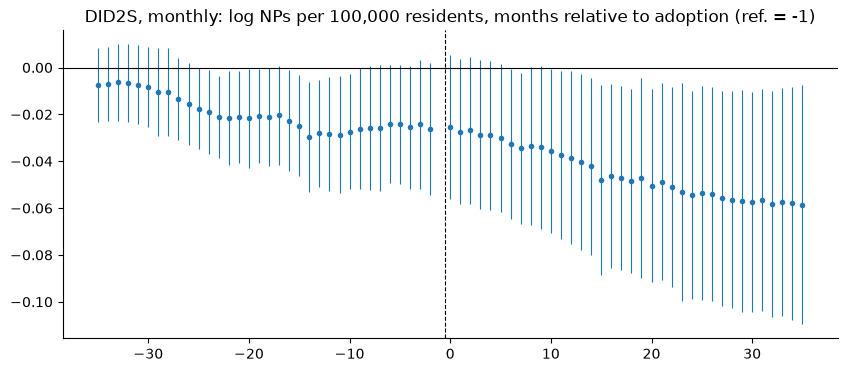

In [11]:
# Gardner DID2S on the monthly panel, dynamic effects on log NPs per 100k, binned at +-36 months
est = con.table("did_state_month").df()
est["treat"] = (est.g.notna() & (est.t >= est.g)).astype(int)
est["rel_b"] = np.where(est.g.notna(), (est.t - est.g).clip(-36, 36), -1000.0)
fit = pf.did2s(est, yname="log_nps_per_100k", first_stage="~ 0 | sid + t", second_stage="~ i(rel_b, ref=-1)", treatment="treat", cluster="sid")
tidy = fit.tidy()
tidy["k"] = tidy.index.str.extract(r"::(-?[\d.]+)")[0].astype(float).values
tidy = tidy[(tidy.k > -1000) & (tidy.k.abs() < 36)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(tidy.k, tidy.Estimate, yerr=1.96 * tidy["Std. Error"], fmt="o", ms=3, lw=0.8)
ax.axhline(0, color="k", lw=0.8); ax.axvline(-0.5, color="k", ls="--", lw=0.8)
ax.set_title("DID2S, monthly: log NPs per 100,000 residents, months relative to adoption (ref. = -1)"); plt.show()

### Reading the estimates

* **Stock.** The average effect on NPs per capita is *negative*: about 5% fewer NPs per resident than the never-treated comparison implies (ATT -0.05 log points, standard error 0.03), with the Callaway-Sant'Anna dynamics flat before adoption and drifting to about -7% by five years after. The monthly two-stage estimator tells a less tidy story: relative to the month before adoption, the treated-minus-control gap was *rising* through the three pre-adoption years and falls afterwards, a hump that could be anticipation, mean reversion, or the choice of reference month. Either way, the comparison group matters: the never-treated states are heavy with Texas, Florida, Georgia and the Carolinas, whose NP counts grow fast for reasons that have nothing to do with scope of practice. The next cell swaps in not-yet-treated controls and the AANP classification; a paper would add region-by-time effects and population weights.
* **Entry and moves.** No detectable change in the rate at which new NPs appear, or in moves in or out, and the confidence bands are wide relative to the pre-adoption means. Across seventeen adoptions, the in-migration margin that the border literature worries about is flat.
* **Independence.** The sole-proprietor share does not move on average, which is the surprising one given the survey and job-posting results on self-employment. Two caveats: CMS's flag is self-reported and only means "unincorporated individual", and eleven FPA states impose a time-in-practice period of one to three years before an NP can drop the practice agreement, which would push any effect past the window shown here.

None of this contradicts Maryland. It says Maryland is not the average adoption, and that the average adoption did not add NPs.

In [12]:
# sensitivity: not-yet-treated controls, and the AANP classification
def simple_att(data, control_group):
    att = ATTgt(data=data.set_index(["sid", "t"]), cohort_column="g")
    att.fit(formula="log_nps_per_100k", control_group=control_group, progress_bar=False)
    return att.aggregate("simple").iloc[0, :2].values

# AANP: treated only if AANP also calls the state full practice; IL, VA, WV become never-treated
aanp = quarterly.assign(g=quarterly.g.where(quarterly.aanp_full_practice))
rows = [("never treated, M&M dates", *simple_att(quarterly, "never_treated")),
        ("not yet treated, M&M dates", *simple_att(quarterly, "not_yet_treated")),
        ("never treated, AANP classification", *simple_att(aanp, "never_treated"))]
pd.DataFrame(rows, columns=["specification", "ATT log NPs per 100k", "se"]).set_index("specification")

,ATT log NPs per 100k,se
specification,,
"never treated, M&M dates",-0.051,0.034
"not yet treated, M&M dates",-0.045,0.033
"never treated, AANP classification",-0.071,0.038


## 6. Who moves into an adopting state, and do they go independent?

The panel identifies each mover, so we can ask whether the NPs who arrive in a state after it adopts FPA look different from those who arrive elsewhere: where they came from, and whether they set up as sole proprietors within a year. Each move is grouped by its destination: a state in its first 24 months of FPA, a state that never adopted, or other. The origin counts as an FPA state only if its law was in force on the move date. "Sole proprietor within a year" means a switch into sole-proprietor status in the 12 months after the move.

In [13]:
con.execute("""
CREATE TABLE np_moves AS
WITH moves AS (
    SELECT npi, date, state, from_state FROM np_events WHERE event = 'move' AND state IN (SELECT state FROM states)
),
sole_prop AS (
    SELECT npi, date FROM np_events WHERE event = 'became_sole_proprietor' AND state IN (SELECT state FROM states)
)
SELECT m.*,
       CASE WHEN dest.coding = 'statute' AND date_diff('month', dest.fpa_effective, m.date) BETWEEN 0 AND 24
                THEN 'into FPA state, first 2 years'
            WHEN dest.coding = 'never' THEN 'into never-FPA state'
            ELSE 'other' END AS destination,
       coalesce(orig.coding = 'always' OR (orig.coding = 'statute' AND orig.fpa_effective <= m.date), false) AS from_fpa_state,
       EXISTS (SELECT 1 FROM sole_prop s
               WHERE s.npi = m.npi AND s.date BETWEEN m.date AND m.date + INTERVAL 1 YEAR) AS sole_prop_within_year
FROM moves m
JOIN fpa_dates dest ON dest.state = m.state
LEFT JOIN fpa_dates orig ON orig.state = m.from_state
""")
con.sql("""
SELECT destination,
       count(*) AS moves,
       avg(from_fpa_state::INT) AS from_an_FPA_state,
       avg(sole_prop_within_year::INT) AS became_sole_proprietor_within_year
FROM np_moves WHERE destination <> 'other'
GROUP BY destination ORDER BY destination
""").df().set_index("destination").style.format({"from_an_FPA_state": "{:.1%}", "became_sole_proprietor_within_year": "{:.1%}"})

,moves,from_an_FPA_state,became_sole_proprietor_within_year
destination,,,
"into FPA state, first 2 years",3580,36.8%,1.5%
into never-FPA state,39453,34.5%,1.4%


Movers into a state in its first two years of FPA look like movers anywhere else in origin and in what they do next: a similar share come from a state where FPA was already in force on the day they moved, and only a few percent set up as sole proprietors within a year. Nothing in the composition of movers suggests the law is pulling in NPs who want to practice independently.

## 7. Border counties for every adoption

Bae et al. compare the counties on each side of the Maryland-Pennsylvania line. With a ZIP to county crosswalk the same comparison can be made for every treated state against every untreated neighbour: NP count in border counties of the adopting state relative to the adjacent counties across the line, indexed to the adoption month.

Each NP is placed in a county by the 2020 ZCTA of the practice ZIP's first five digits, using the county that holds most of the ZCTA's land area. For each cohort, the "own" side is its counties that touch another state. The "across" side is the counties they touch in states that stay untreated for the five years after the cohort adopts. Both sides are counted on every snapshot from 60 months before adoption to 60 after (`k` is months since adoption). Each cohort is indexed to its mean own/across ratio over the four months ending at adoption (`k` from -3 to 0). A cohort is dropped when it has no untreated neighbour counties or a base month with no NPs on either side.

98.4% of NP versions map to a county
MA: skipped (no untreated neighbour counties, or no NPs in the base window)
SD: skipped (no untreated neighbour counties, or no NPs in the base window)
UT: skipped (no untreated neighbour counties, or no NPs in the base window)


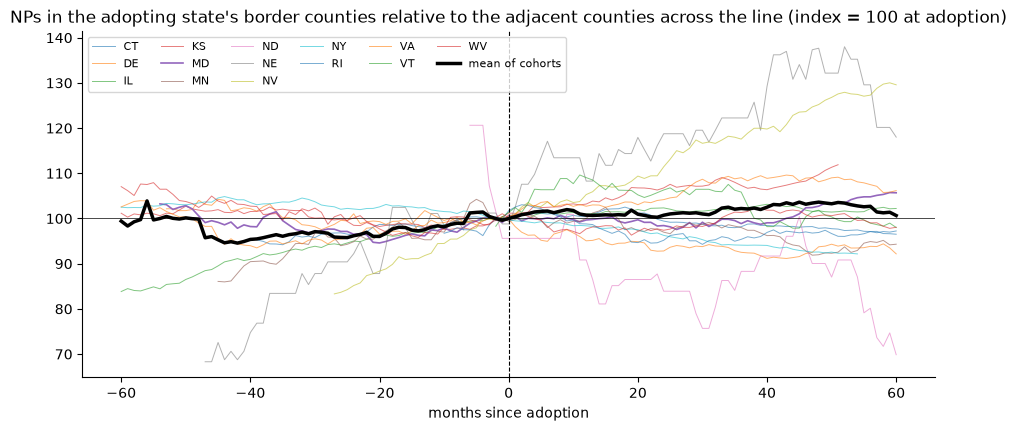

In [14]:
con.execute("""
CREATE TABLE np_county_stock AS
SELECT s.as_of_date AS as_of, z.county_fips AS county, count(*) AS nps
FROM monthly_snapshots s
JOIN np_versions v ON v.effective_date <= s.as_of_date AND (v.end_date IS NULL OR v.end_date > s.as_of_date)
JOIN read_csv('data/zcta_county.csv', all_varchar = true) z ON z.zcta = left(v.practice_postal_code, 5)
WHERE v.is_np
GROUP BY ALL;

CREATE TABLE border_cohort_counties AS
SELECT DISTINCT c.state AS cohort, side.side, side.county
FROM fpa_cohorts c
JOIN states s ON s.state = c.state
JOIN read_csv('data/state_border_county_pairs.csv', all_varchar = true) p ON left(p.county_fips, 2) = s.fips
JOIN states ns ON ns.fips = left(p.neighbor_fips, 2)
JOIN fpa_dates n ON n.state = ns.state
CROSS JOIN LATERAL (VALUES ('own', p.county_fips), ('across', p.neighbor_fips)) side(side, county)
WHERE n.coding = 'never' OR n.fpa_effective > c.fpa_effective + INTERVAL 60 MONTH;

CREATE TABLE border_index AS
WITH series AS (
    SELECT c.state AS cohort, date_diff('month', c.fpa_effective, m.as_of_date) AS k,
           coalesce(sum(n.nps) FILTER (WHERE b.side = 'own'), 0) AS own,
           coalesce(sum(n.nps) FILTER (WHERE b.side = 'across'), 0) AS across
    FROM fpa_cohorts c
    JOIN monthly_snapshots m ON date_diff('month', c.fpa_effective, m.as_of_date) BETWEEN -60 AND 60
    LEFT JOIN border_cohort_counties b ON b.cohort = c.state
    LEFT JOIN np_county_stock n ON n.county = b.county AND n.as_of = m.as_of_date
    GROUP BY ALL
),
base AS (
    SELECT cohort, avg(own / across) AS base_ratio
    FROM series WHERE k BETWEEN -3 AND 0
    GROUP BY cohort
    HAVING count(*) >= 2 AND min(own) > 0 AND min(across) > 0
)
SELECT s.cohort, s.k, s.own, s.across, (s.own / s.across) / b.base_ratio * 100 AS ratio_index
FROM series s JOIN base b USING (cohort)
ORDER BY cohort, k;
""")
mapped = con.sql("""
SELECT avg((z.county_fips IS NOT NULL)::INT) FROM np_versions v
LEFT JOIN read_csv('data/zcta_county.csv', all_varchar = true) z ON z.zcta = left(v.practice_postal_code, 5)
WHERE v.is_np
""").fetchone()[0]
print(f"{mapped:.1%} of NP versions map to a county")
for (st,) in con.sql("SELECT state FROM fpa_cohorts WHERE state NOT IN (SELECT cohort FROM border_index) ORDER BY state").fetchall():
    print(f"{st}: skipped (no untreated neighbour counties, or no NPs in the base window)")
border = con.table("border_index").df()
fig, ax = plt.subplots(figsize=(11, 4.5))
for st, d in border.groupby("cohort"):
    ax.plot(d.k, d.ratio_index, lw=1.2 if st == "MD" else 0.7, label=st, alpha=1 if st == "MD" else 0.6)
mean = border.groupby("k").ratio_index.mean(); ax.plot(mean.index, mean.values, color="k", lw=2.5, label="mean of cohorts")
ax.axvline(0, color="k", ls="--", lw=0.8); ax.axhline(100, color="k", lw=0.5)
ax.set_title("NPs in the adopting state's border counties relative to the adjacent counties across the line (index = 100 at adoption)")
ax.set_xlabel("months since adoption"); ax.legend(ncol=6, fontsize=8); plt.show()

Each cohort is indexed to the mean ratio over the four months ending at adoption. The cohort mean stays within a few points of 100 for five years on either side of adoption. Maryland's border counties gain about five percent on Pennsylvania's within five years, which matches the state-level ratio in section 3 (the larger divergence comes later). The average adopting state does not gain NPs at its border relative to its untreated neighbours, which is consistent with the state-level estimates. Individual cohorts swing by 20 or 30 points because some border strips hold only a few hundred NPs.

## 8. What to be careful about

* **Practice address is one address.** NPPES holds a primary practice location (and, since July 2018, secondary locations in the `practice_location` table). NPs who work in several states appear once, where they put their primary address.
* **Sole proprietor is a CMS flag**, self-reported at enumeration or update, meaning an unincorporated individual. An NP who owns a practice through an LLC is not a sole proprietor; the 34,000 *organization* NPIs with an NP primary taxonomy would be a second place to look for NP-owned practices.
* **Time-in-practice rules.** Eleven FPA states require one to three years of supervised practice first, so the effective date of the law is not the date most NPs could use it.
* **Classification.** The McMichael and Markowitz and AANP codings disagree on four states; the sensitivity table shows the estimate is not driven by that choice.
* **Design.** Staggered adoption with a never-treated group that grows faster than the treated states before treatment. The pre-trend is visible and small; a paper would control for region-by-time or compare to not-yet-treated states, both of which this notebook shows how to do.
* **The panel is monthly from April 2011**, so the adoptions in Arizona, Hawaii, Colorado, Idaho and Washington cannot be used, and the Maryland 2010 attestation rule (which McMichael and Markowitz treat as the first FPA step) falls in the sparse years.

## 9. Where a researcher would go next

* Link the NPIs to Medicare or all-payer claims to see utilization, billing under the NP's own NPI, and patient panels, by month relative to adoption.
* Use `provider_taxonomy.license_state` across slots to measure multi-state licensure, and `practice_location` to count NPs practicing across a border without moving.
* Use the organization NPIs with NP taxonomies to date the opening of NP-owned practices.
* The same pipeline works for any taxonomy family: change the `363L` prefix in the `np_versions` cell for physician assistants (`363A`), certified registered nurse anesthetists (`367500000X`) or pharmacists (`1835`) and replace `data/np_fpa_dates.csv` with their scope-of-practice laws.